<a href="https://colab.research.google.com/github/RohitRevankarDev/AML-Assignment-261100610035/blob/main/3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, silhouette_score, adjusted_rand_score
)

print("Libraries imported successfully.")


Libraries imported successfully.


In [3]:

# Load the Diabetes dataset
data_reg = load_diabetes(as_frame=True)
X = data_reg.data
y = data_reg.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=20000)
}

regression_results = []

for name, estimator in regression_models.items():
    model = make_pipeline(StandardScaler(), estimator)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    mse = mean_squared_error(y_test, pred)

    regression_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, pred)
    })

regression_df = pd.DataFrame(regression_results)
display(regression_df.round(4))


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,42.7941,2900.1936,53.8534,0.4526
1,Ridge Regression,42.8120,2892.0146,53.7775,0.4541
2,Lasso Regression,42.7950,2898.3680,53.8365,0.4529


In [4]:

data_clf = load_breast_cancer(as_frame=True)
X = data_clf.data
y = data_clf.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

classification_models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000, random_state=42)
    ),
    "KNN": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    "Naive Bayes": GaussianNB(),
    "Bagging": BaggingClassifier(n_estimators=100, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42)
}

classification_results = []

for name, model in classification_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

classification_df = pd.DataFrame(classification_results)
display(classification_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,0.9211,0.9565,0.9167,0.9362,0.9163
1,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
2,KNN,0.9561,0.9589,0.9722,0.9655,0.9788
3,Naive Bayes,0.9386,0.9452,0.9583,0.9517,0.9878
4,Bagging,0.9386,0.9452,0.9583,0.9517,0.9927
5,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9937
6,AdaBoost,0.9561,0.9467,0.9861,0.9660,0.9818


In [5]:

data_cluster = load_iris(as_frame=True)
X = StandardScaler().fit_transform(data_cluster.data)
y = data_cluster.target

clustering_models = {
    "K-Means": KMeans(n_clusters=3, n_init=10, random_state=42),
    "Hierarchical (Ward)": AgglomerativeClustering(
        n_clusters=3, linkage="ward"
    ),
    "Hierarchical (Complete)": AgglomerativeClustering(
        n_clusters=3, linkage="complete"
    ),
    "Gaussian Mixture": GaussianMixture(
        n_components=3, n_init=10, random_state=42
    )
}

clustering_results = []

for name, model in clustering_models.items():
    labels = model.fit_predict(X)

    clustering_results.append({
        "Model": name,
        "Silhouette Score": silhouette_score(X, labels),
        "Adjusted Rand Index": adjusted_rand_score(y, labels)
    })

clustering_df = pd.DataFrame(clustering_results)
display(clustering_df.round(4))


,Model,Silhouette Score,Adjusted Rand Index
0,K-Means,0.4599,0.6201
1,Hierarchical (Ward),0.4467,0.6153
2,Hierarchical (Complete),0.4496,0.5726
3,Gaussian Mixture,0.3742,0.9039


,Original Features,Reduced Features,Explained Variance,Reconstruction MSE
0,30,2,0.6324,0.3676


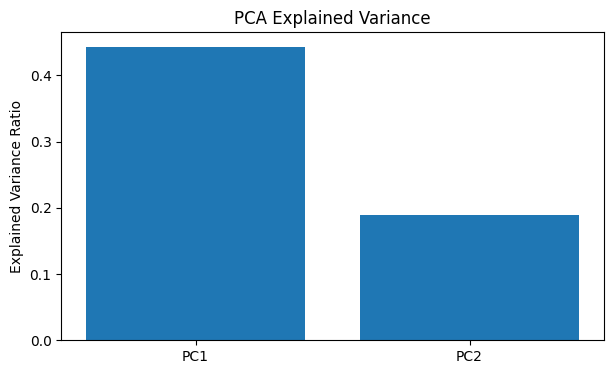

In [6]:

data_pca = load_breast_cancer(as_frame=True)

X_scaled = StandardScaler().fit_transform(data_pca.data)

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_scaled)

X_reconstructed = pca.inverse_transform(X_reduced)

explained_variance = pca.explained_variance_ratio_.sum()
reconstruction_mse = mean_squared_error(X_scaled, X_reconstructed)

pca_results = pd.DataFrame([{
    "Original Features": X_scaled.shape[1],
    "Reduced Features": X_reduced.shape[1],
    "Explained Variance": explained_variance,
    "Reconstruction MSE": reconstruction_mse
}])

display(pca_results.round(4))

plt.figure(figsize=(7, 4))
plt.bar(
    ["PC1", "PC2"],
    pca.explained_variance_ratio_
)
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.show()


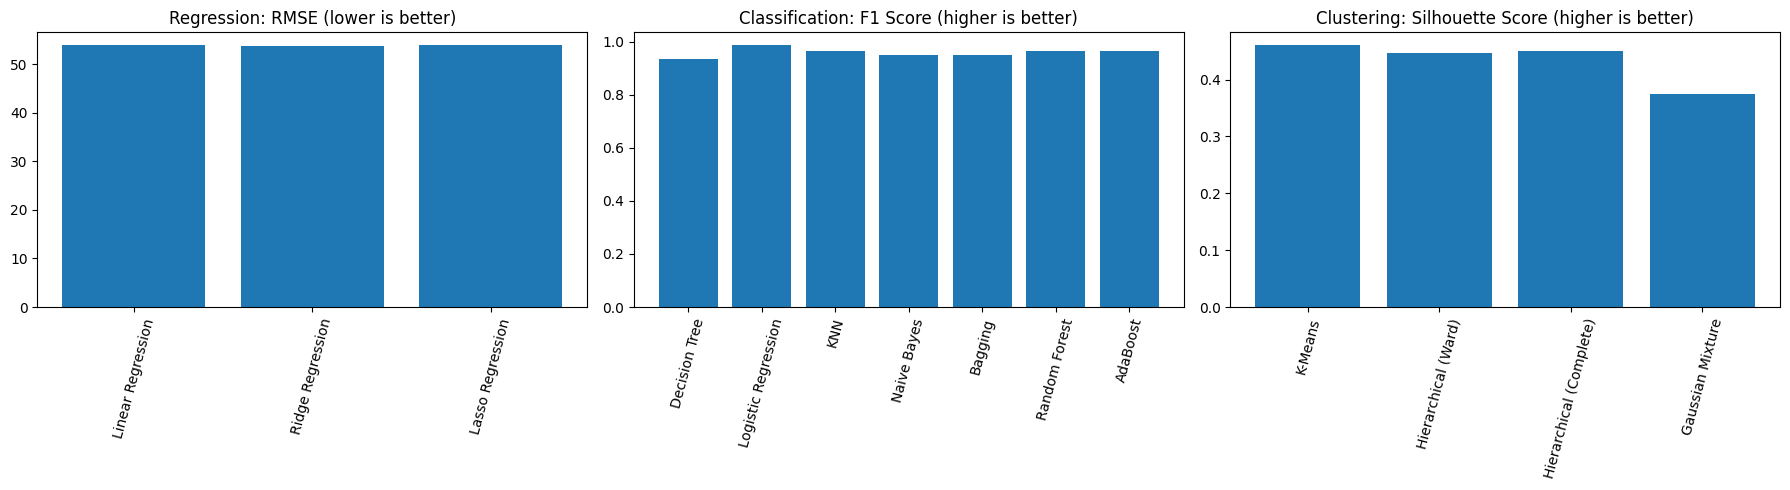

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].bar(regression_df["Model"], regression_df["RMSE"])
axes[0].set_title("Regression: RMSE (lower is better)")
axes[0].tick_params(axis="x", rotation=75)

axes[1].bar(classification_df["Model"], classification_df["F1 Score"])
axes[1].set_title("Classification: F1 Score (higher is better)")
axes[1].tick_params(axis="x", rotation=75)

axes[2].bar(
    clustering_df["Model"],
    clustering_df["Silhouette Score"]
)
axes[2].set_title("Clustering: Silhouette Score (higher is better)")
axes[2].tick_params(axis="x", rotation=75)

plt.tight_layout()
plt.show()



# Result and Conclusion

## Result

The performance of regression, classification, clustering and dimensionality reduction models was evaluated using appropriate metrics.

- Regression models were compared using MAE, MSE, RMSE and R².
- Classification models were compared using accuracy, precision, recall, F1-score and ROC-AUC.
- Clustering algorithms were evaluated using Silhouette Score and Adjusted Rand Index.
- PCA was analysed using explained variance and reconstruction MSE.

## Conclusion

Different machine learning models were evaluated using suitable performance metrics. Lower regression errors indicate better predictions, while higher R², classification scores and silhouette scores generally indicate better performance. PCA reduced the number of features while retaining part of the original data's variance.

The most suitable model depends on the dataset, evaluation metric and objective of the task.
